# Happiness Factors by Income Level and Region

Do the same factors matter everywhere? Correlation heatmaps for all countries, the 20 happiest vs. the 20 least happy, and broad regional groups.

In [1]:
import sys
from pathlib import Path

# Make happiness.py importable whether Jupyter starts in JupyterCodes/ or the repo root
for folder in (Path.cwd(), Path.cwd().parent):
    if (folder / "happiness.py").exists():
        sys.path.insert(0, str(folder))
        break

import matplotlib.pyplot as plt
import pandas as pd
import happiness as hp

df = hp.load_data()
print(f"{len(df)} countries, {df[hp.REGION].nunique()} regions")

149 countries, 10 regions


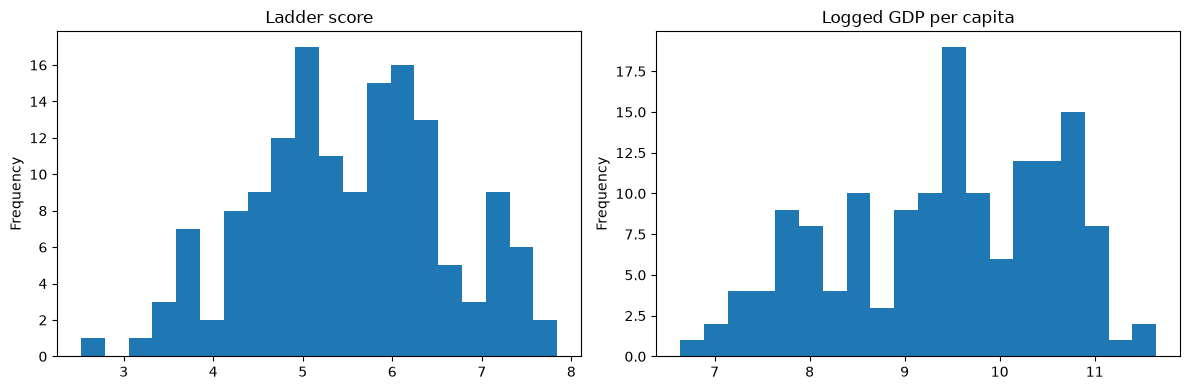

Average ladder score: 5.53


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df[hp.SCORE].plot.hist(bins=20, ax=axes[0], title="Ladder score")
df["Logged GDP per capita"].plot.hist(bins=20, ax=axes[1], title="Logged GDP per capita")
plt.tight_layout()
plt.show()
print(f"Average ladder score: {df[hp.SCORE].mean():.2f}")

## All countries

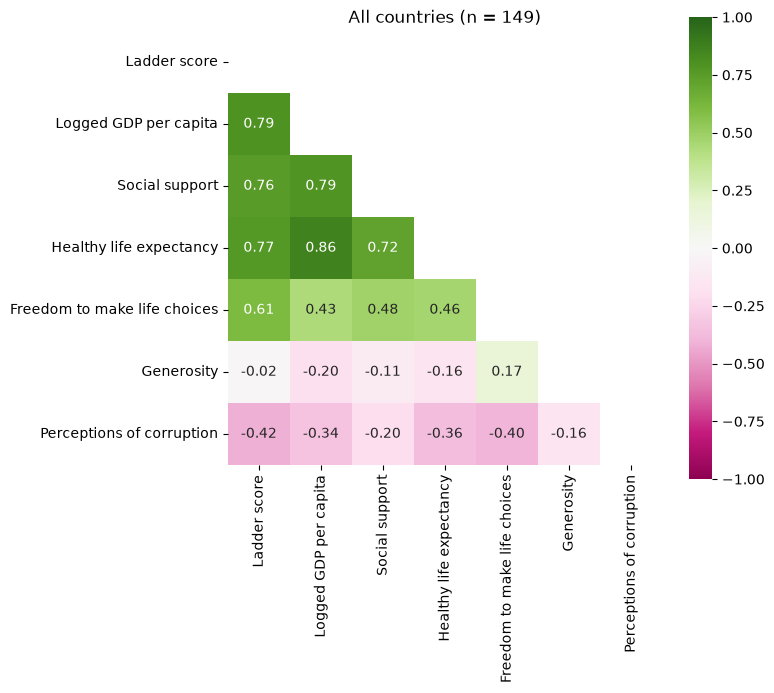

In [3]:
fig = hp.corr_heatmap(df, "All countries")
plt.show()

## 20 happiest vs. 20 least happy countries

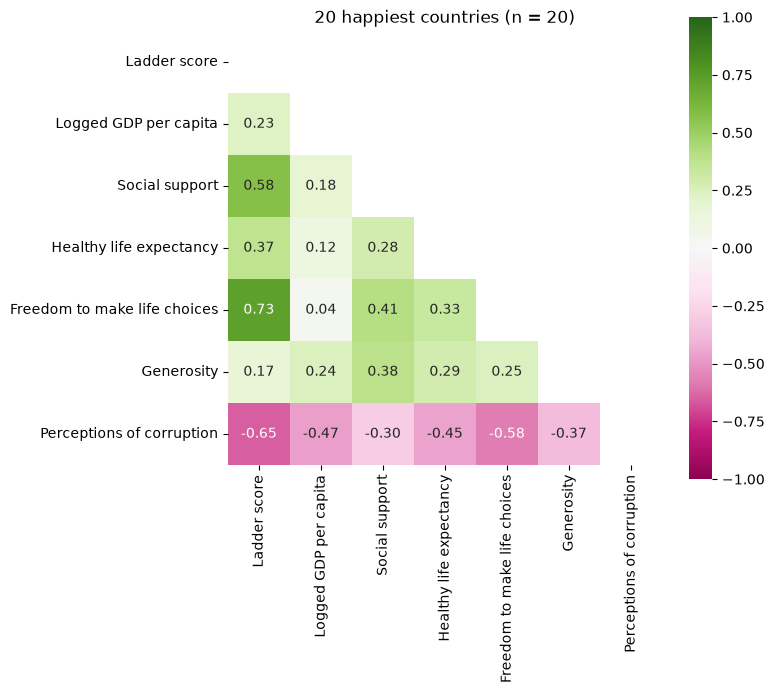

In [4]:
top, bottom = hp.top_and_bottom(df, 20)
fig = hp.corr_heatmap(top, "20 happiest countries")
hp.save(fig, "Top20.png")
plt.show()

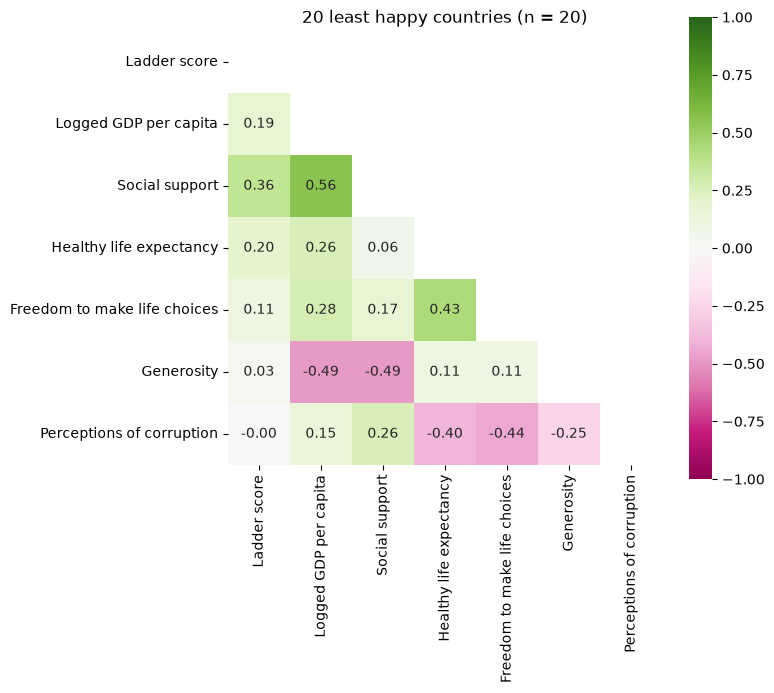

Average logged GDP — top 20: 10.86, bottom 20: 7.97


In [5]:
fig = hp.corr_heatmap(bottom, "20 least happy countries")
hp.save(fig, "Lowest20.png")
plt.show()
print(f"Average logged GDP — top 20: {top['Logged GDP per capita'].mean():.2f}, bottom 20: {bottom['Logged GDP per capita'].mean():.2f}")

Among the happiest countries, freedom and perceived corruption matter far more than GDP. Among the least happy, no factor is strongly related to the score.

## Regional groups

Each of the report's 10 regions is assigned to exactly one group (see `REGION_GROUPS` in `happiness.py`).

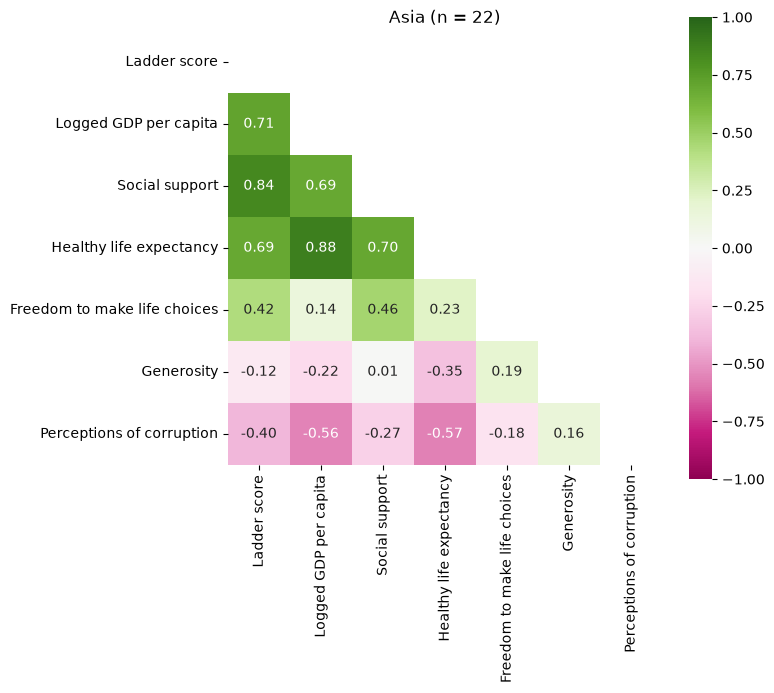

In [6]:
fig = hp.corr_heatmap(hp.region_group(df, "Asia"), "Asia")
hp.save(fig, "Asia.png")
plt.show()

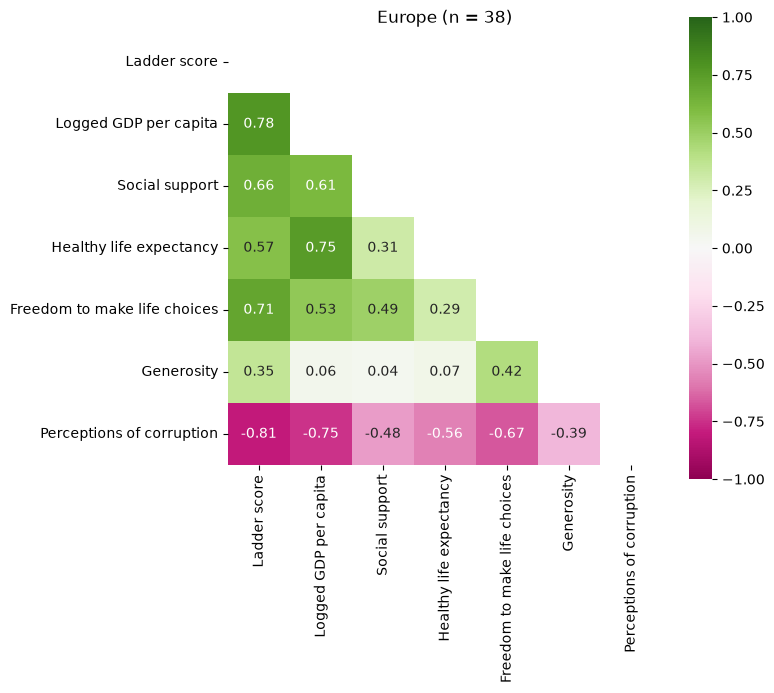

In [7]:
fig = hp.corr_heatmap(hp.region_group(df, "Europe"), "Europe")
hp.save(fig, "Europe.png")
plt.show()

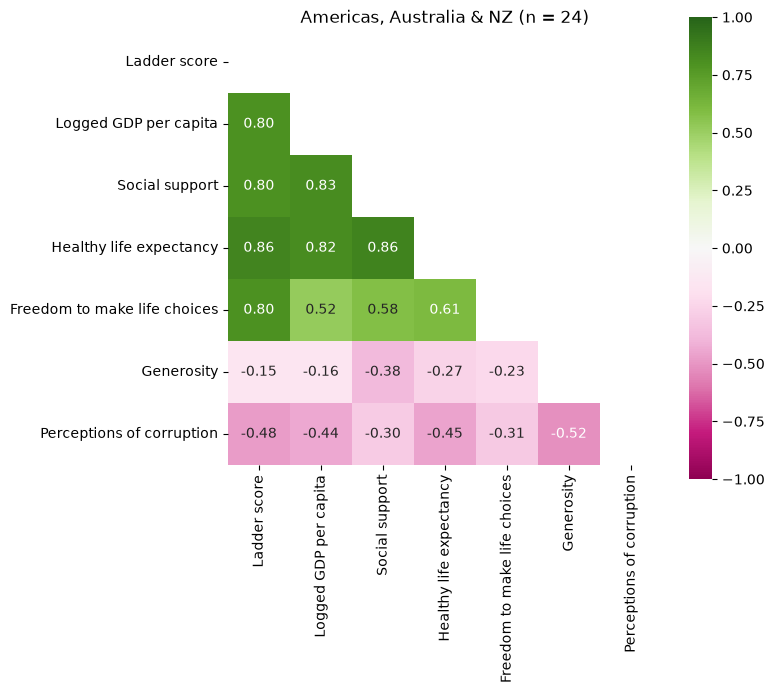

In [8]:
fig = hp.corr_heatmap(hp.region_group(df, "Americas, Australia & NZ"), "Americas, Australia & NZ")
hp.save(fig, "america.png")
plt.show()

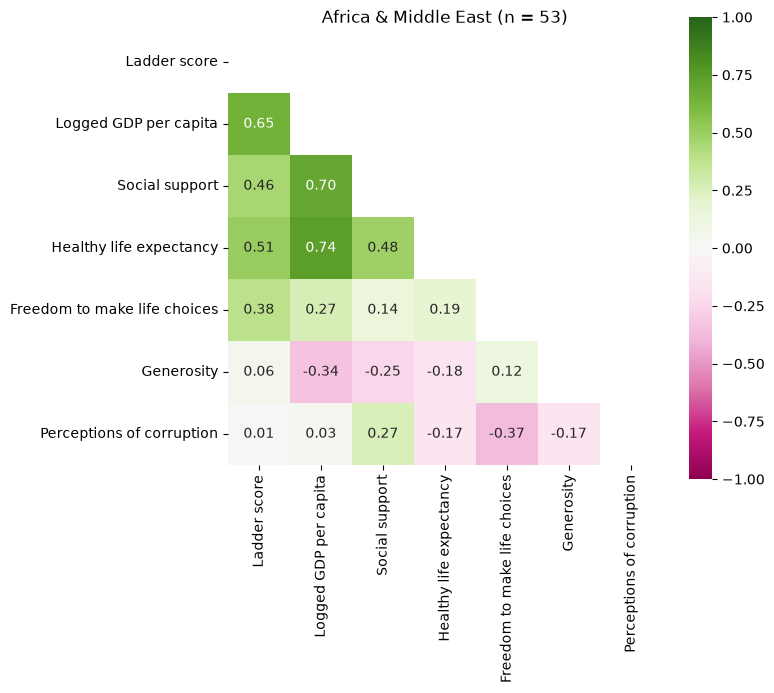

In [9]:
fig = hp.corr_heatmap(hp.region_group(df, "Africa & Middle East"), "Africa & Middle East")
hp.save(fig, "Africa.png")
plt.show()

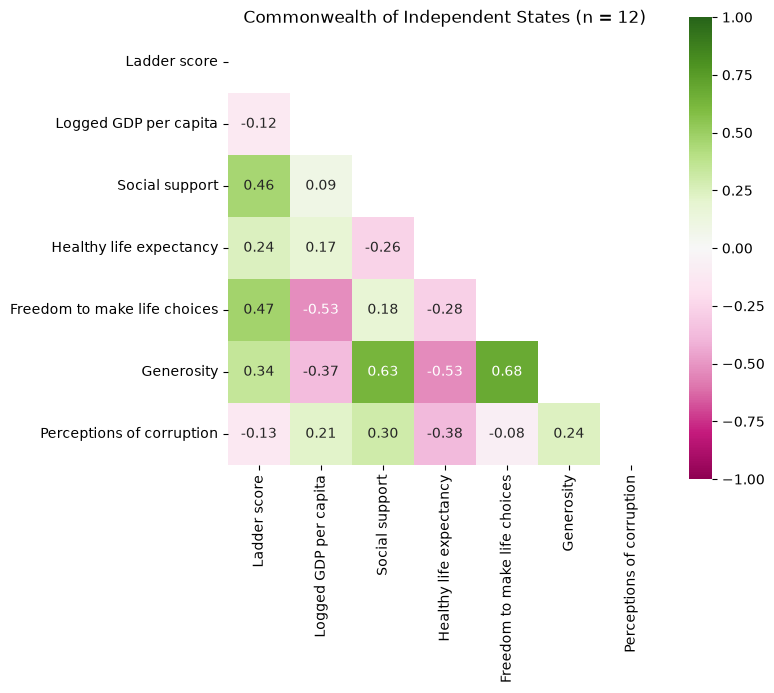

In [10]:
fig = hp.corr_heatmap(hp.region_group(df, "Commonwealth of Independent States"), "Commonwealth of Independent States")
hp.save(fig, "Other Countries.png")
plt.show()

## World map

In [11]:
import plotly.express as px

fig = px.choropleth(df, locations="Country name", locationmode="country names", color=hp.SCORE,
                    hover_name="Country name", color_continuous_scale="Viridis",
                    title="Global Happiness 2021")
fig.show()